In [76]:
import pandas as pd
import numpy as np
# importing numpy and pandas

np.random.seed(42)

pd.set_option('display.max_columns', None)

# Show all rows (disables row truncation)
pd.set_option('display.max_rows', None)

# Optional: expand width so lines don't wrap awkwardly
pd.set_option('display.width', 1000)
n = 100
study_hours = np.random.normal(5, 2, n)
attendance = np.random.normal(85, 10, n)
previous_mark = np.random.normal(70, 15, n)
final_score = (0.5 * study_hours) + (0.3 * attendance) + (0.2 * previous_mark) + np.random.normal(0, 5, n)
df = pd.DataFrame({
'study_hours': study_hours,
'attendance': attendance,
'previous_mark': previous_mark,
'final_score': final_score
})

df.loc[0:5, 'study_hours'] = np.nan # Missing values
df.loc[99, 'study_hours'] = 50 # Outlier
df.loc[98, 'attendance'] = -10 # Impossible value

print(df)
# df.to_csv('student_data.csv', index=False)

    study_hours  attendance  previous_mark  final_score
0           NaN   70.846293      75.366810    35.178989
1           NaN   80.793547      78.411768    39.481248
2           NaN   81.572855      86.245769    48.605167
3           NaN   76.977227      85.807031    47.329456
4           NaN   83.387143      49.334959    37.044473
5           NaN   89.040509      55.932624    40.751177
6      8.158426  103.861859      77.725529    57.171201
7      6.534869   86.745778      77.706789    41.874669
8      4.061051   87.575504      77.725715    46.583807
9      6.085120   84.255541     127.790972    52.866454
10     4.073165   65.812288      78.563358    36.404534
11     4.068540   84.734861      87.033485    50.355310
12     5.483925   85.602302      84.310026    49.411740
13     1.173440  109.632421      79.770869    53.498168
14     1.550164   83.076390      65.270961    45.279586
15     3.875425   88.015473      81.384538    44.724281
16     2.974338   84.652882      58.407622    41

In [77]:

# Clean the dataset

#  Fill missing study_hours with the median
study_median = df["study_hours"].median()
df["study_hours"] = df["study_hours"].fillna(study_median)

# Cap the outlier at the highest value among the other students
max_hours = df.loc[df.index != 99, "study_hours"].max()
df.loc[99, "study_hours"] = max_hours

# Replace impossible attendance (-10) with the median
valid_attendance = df.loc[df.index != 98, "attendance"]
attendance_median = valid_attendance.median()
df.loc[98, "attendance"] = attendance_median

# Display the cleaned rows
print("Cleaning completed!")
print(df.loc[[0,1,2,3,4, 5, 98, 99]])


Cleaning completed!
    study_hours  attendance  previous_mark  final_score
0      4.812342   70.846293      75.366810    35.178989
1      4.812342   80.793547      78.411768    39.481248
2      4.812342   81.572855      86.245769    48.605167
3      4.812342   76.977227      85.807031    47.329456
4      4.812342   83.387143      49.334959    37.044473
5      4.812342   89.040509      55.932624    40.751177
98     5.010227   85.996514      82.192932    44.045627
99     8.704556   73.570297      79.444433    46.414470


In [78]:

# Select the input features
X = df[["study_hours", "attendance", "previous_mark"]]

# Select the target variable
y = df["final_score"]

print("Feature matrix shape:", X.shape)
print("Numerical columns:", df.select_dtypes(include="number").columns.tolist())
print("Target variable:", y.name)


Feature matrix shape: (100, 3)
Numerical columns: ['study_hours', 'attendance', 'previous_mark', 'final_score']
Target variable: final_score


The shape of the feature matrix is (100, 3), which means it contains 100 rows and 3 feature columns. The numerical columns are study_hours, attendance, previous_mark, and final_score. The target variable is final_score because it is the value we want to predict.

The outlier is the value \50 hours in the study_hours column at row 99. I chose to cap the value because keeping the student helps preserve the dataset. I replaced it with the maximum study-hours value among the other students to reduce the effect of the outlier while keeping all 100 students in the dataset.

In [79]:

print("Mean:")
print(df.mean())

print("\nMedian:")
print(df.median())

print("\nStandard Deviation:")
print(df.std())


Mean:
study_hours       4.781567
attendance       85.227190
previous_mark    70.973444
final_score      42.691957
dtype: float64

Median:
study_hours       4.812342
attendance       85.996514
previous_mark    71.465436
final_score      42.763014
dtype: float64

Standard Deviation:
study_hours       1.818557
attendance        9.536937
previous_mark    16.264243
final_score       6.086797
dtype: float64


1. **Study hours:** The mean is 4.78 hours, and the median is 4.81 hours. These values are very close, which suggests that the study-hours values are fairly balanced around the center.

2. **Attendance:** The mean attendance is 85.23, and the standard deviation is 9.54. This shows that the students' attendance values vary around the average of approximately 85.23.

3. **Previous marks and final scores:** Previous marks have a standard deviation of 16.26, while final scores have a standard deviation of 6.09. This means previous marks are more spread out than final scores in this dataset.

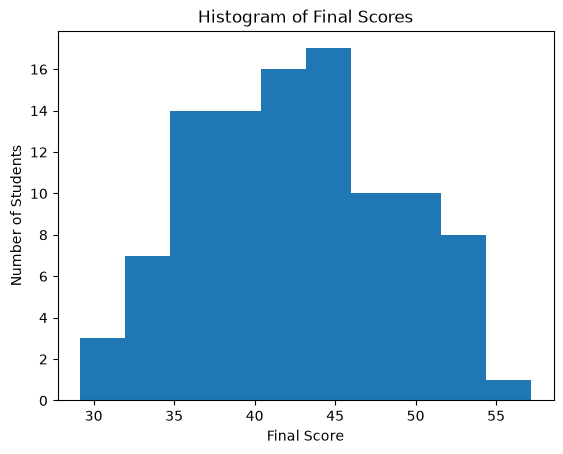

In [80]:

import matplotlib.pyplot as plt

# Create a histogram
plt.hist(df["final_score"], bins=10)

plt.title("Histogram of Final Scores")
plt.xlabel("Final Score")
plt.ylabel("Number of Students")

plt.show()


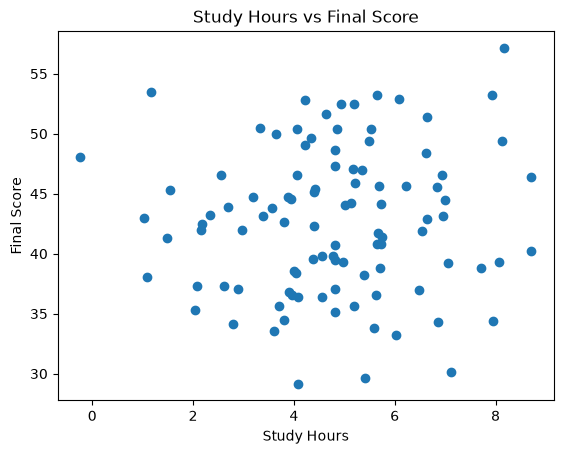

In [81]:

# Create a scatter plot
plt.scatter(df["study_hours"], df["final_score"])

plt.title("Study Hours vs Final Score")
plt.xlabel("Study Hours")
plt.ylabel("Final Score")

plt.show()


The scatter plot shows a weak positive relationship between study hours and final scores. In general, students who study more hours tend to have slightly higher final scores. However, the points are widely spread, meaning that studying hours alone does not strongly predict a student's final score.

In [82]:

# Calculate Pearson correlation
correlation = df["study_hours"].corr(df["final_score"])

print("Pearson correlation coefficient:", correlation)


Pearson correlation coefficient: 0.0617471199566707


No. Correlation not guarantee that a student who studies 10 hours will receive a specific score. Correlation describes how two variables are related, but it does not give an exact score for an individual student.

A possible confounding variable is attendance. Students who attend more classes may understand the lessons better and may also spend more time studying. Therefore, attendance could help explain the relationship between study hours and final scores.

In [83]:

# Select one student's features
x = df.loc[0, ["study_hours", "attendance", "previous_mark"]].to_numpy()

# Define the weight vector and bias
w = np.array([0.5, 0.2, 0.4])
b = 5

# Calculate y = w dot x + b
result = np.dot(w, x) + b

print("Student vector:", x)
print("Weight vector:", w)
print("Bias:", b)
print("Calculated result:", result)


Student vector: [ 4.8123416  70.84629258 75.36681041]
Weight vector: [0.5 0.2 0.4]
Bias: 5
Calculated result: 51.722153476004586


The weight vector represents how much each feature contributes to the calculated score. Each weight is multiplied by its corresponding feature value.

The bias is added after the dot product. It allows the calculated result to be shifted by a constant value.